Inspect WikiArt Dataset and Style Distribution

In [19]:
from datasets import load_dataset

ds = load_dataset(
    "huggan/wikiart",
    split="train"
)

style_names = ds.features["style"].names

print("Total images:", len(ds))
print("Columns:", ds.column_names)
print("Number of styles:", len(style_names))

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/45 [00:00<?, ?it/s]

Total images: 81444
Columns: ['image', 'artist', 'genre', 'style']
Number of styles: 27


In [20]:
import numpy as np
import pandas as pd
from pathlib import Path

# =========================================================
# 1. Configuration
# =========================================================

SEED = 42

TRAIN_PER_STYLE = 500
VAL_PER_STYLE = 100

# Images identified by the leakage audit as
EXCLUDED_INDICES = {
    33690,
    52178,
    38174,
    36400,
    33927,
    32117,
    53696
}
SELECTED_STYLES = [
    "Impressionism",
    "Realism",
    "Expressionism",
    "Cubism",
    "Abstract_Expressionism"
]

PROJECT_ROOT = Path("/home/jovyan/AI_summer_shool_Aesha")

TRAINING_DIR = PROJECT_ROOT / "training_data"
TRAINING_DIR.mkdir(parents=True, exist_ok=True)

SPLIT_PATH = TRAINING_DIR / "wikiart_style_splits.csv"

rng = np.random.default_rng(SEED)

# =========================================================
# 2. Style IDs
# =========================================================

style_names = ds.features["style"].names

style_to_id = {
    style_name: style_names.index(style_name)
    for style_name in SELECTED_STYLES
}

selected_style_ids = set(style_to_id.values())

print("Selected styles:")

for style_name, style_id in style_to_id.items():
    print(f"{style_name}: {style_id}")

# =========================================================
# 3. Build candidate table WITHOUT loading images
# =========================================================

artists = ds["artist"]
styles = ds["style"]

rows = []

for idx, (artist, style_id) in enumerate(
    zip(artists, styles)
):
    style_id = int(style_id)

    # Skip images identified as cross-split duplicates
    if idx in EXCLUDED_INDICES:
        continue

    if style_id not in selected_style_ids:
        continue

    if artist is None or str(artist).strip() == "":
        continue

    rows.append({
        "dataset_index": idx,
        "style": style_names[style_id],
        "style_label": style_id,
        "artist": str(artist)
    })

pool_df = pd.DataFrame(rows)

print("\nAvailable images after exclusions:")

print(
    pool_df["style"]
    .value_counts()
    .reindex(SELECTED_STYLES)
)

# =========================================================
# 4. Count images per artist and style
# =========================================================

artist_style_counts = pd.crosstab(
    pool_df["artist"],
    pool_df["style"]
).reindex(
    columns=SELECTED_STYLES,
    fill_value=0
)

total_per_style = (
    pool_df["style"]
    .value_counts()
    .reindex(SELECTED_STYLES)
    .to_numpy()
)

# =========================================================
# 5. Select validation artists globally
# =========================================================

val_target = np.full(
    len(SELECTED_STYLES),
    VAL_PER_STYLE,
    dtype=int
)

val_available = np.zeros(
    len(SELECTED_STYLES),
    dtype=int
)

excluded_from_train = np.zeros(
    len(SELECTED_STYLES),
    dtype=int
)

remaining_artists = list(artist_style_counts.index)

# Shuffle first so ties do not depend on alphabetical order
rng.shuffle(remaining_artists)

validation_artists = set()

while np.any(val_available < val_target):

    deficits = np.maximum(
        val_target - val_available,
        0
    )

    best_artist = None
    best_score = -1

    for artist in remaining_artists:

        counts = artist_style_counts.loc[
            artist
        ].to_numpy(dtype=int)

        # Artist must contribute to an unfinished
        # validation style.
        useful = np.minimum(
            counts,
            deficits
        ).sum()

        if useful == 0:
            continue

        # If this artist becomes validation-only,
        # none of their images can be training data.
        new_excluded = (
            excluded_from_train + counts
        )

        train_remaining = (
            total_per_style - new_excluded
        )

        # Preserve enough possible training images
        # for every style.
        if np.any(
            train_remaining < TRAIN_PER_STYLE
        ):
            continue

        # Prefer artists that satisfy validation needs
        # while removing relatively few training images.
        total_artist_images = counts.sum()

        score = useful / total_artist_images

        if score > best_score:
            best_score = score
            best_artist = artist

    if best_artist is None:
        print("\nUnable to satisfy all targets.")

        print(
            "Validation currently available:",
            dict(zip(
                SELECTED_STYLES,
                val_available
            ))
        )

        print(
            "Still required:",
            dict(zip(
                SELECTED_STYLES,
                np.maximum(
                    val_target - val_available,
                    0
                )
            ))
        )

        raise RuntimeError(
            "Artist-disjoint 500/100 split is not feasible "
            "with the current constraints."
        )

    counts = artist_style_counts.loc[
        best_artist
    ].to_numpy(dtype=int)

    validation_artists.add(best_artist)

    val_available += counts
    excluded_from_train += counts

    remaining_artists.remove(best_artist)

# =========================================================
# 6. Split candidate pools
# =========================================================

validation_pool = pool_df[
    pool_df["artist"].isin(validation_artists)
].copy()

training_pool = pool_df[
    ~pool_df["artist"].isin(validation_artists)
].copy()

# =========================================================
# 7. Sample exact balanced counts
# =========================================================

final_records = []

for style_name in SELECTED_STYLES:

    train_candidates = training_pool[
        training_pool["style"] == style_name
    ]

    val_candidates = validation_pool[
        validation_pool["style"] == style_name
    ]

    print(f"\n{style_name}")
    print(
        "Training candidates:",
        len(train_candidates)
    )
    print(
        "Validation candidates:",
        len(val_candidates)
    )

    if len(train_candidates) < TRAIN_PER_STYLE:
        raise RuntimeError(
            f"Not enough training images for {style_name}"
        )

    if len(val_candidates) < VAL_PER_STYLE:
        raise RuntimeError(
            f"Not enough validation images for {style_name}"
        )

    train_sample = train_candidates.sample(
        n=TRAIN_PER_STYLE,
        random_state=SEED
    ).copy()

    val_sample = val_candidates.sample(
        n=VAL_PER_STYLE,
        random_state=SEED
    ).copy()

    train_sample["split"] = "train"
    val_sample["split"] = "validation"

    final_records.append(train_sample)
    final_records.append(val_sample)

# =========================================================
# 8. Final split
# =========================================================

split_df = pd.concat(
    final_records,
    ignore_index=True
)

# =========================================================
# 9. Verification
# =========================================================

assert len(split_df) == 3000
assert split_df["dataset_index"].is_unique

assert (
    split_df["split"] == "train"
).sum() == 2500

assert (
    split_df["split"] == "validation"
).sum() == 500

train_artists = set(
    split_df.loc[
        split_df["split"] == "train",
        "artist"
    ]
)

val_artists = set(
    split_df.loc[
        split_df["split"] == "validation",
        "artist"
    ]
)

shared_artists = train_artists & val_artists

assert len(shared_artists) == 0

# =========================================================
# 10. Save ONLY the final split registry
# =========================================================

split_df.to_csv(
    SPLIT_PATH,
    index=False
)

print("\n" + "=" * 55)
print("FINAL DATASET SPLIT")
print("=" * 55)

print("\nTraining distribution:")
print(
    split_df[
        split_df["split"] == "train"
    ]["style"].value_counts()
)

print("\nValidation distribution:")
print(
    split_df[
        split_df["split"] == "validation"
    ]["style"].value_counts()
)

print("\nTraining images:", 2500)
print("Validation images:", 500)

print(
    "Training artists:",
    len(train_artists)
)

print(
    "Validation artists:",
    len(val_artists)
)

print(
    "Shared artists:",
    len(shared_artists)
)

print("\nSaved:")
print(SPLIT_PATH)

Selected styles:
Impressionism: 12
Realism: 21
Expressionism: 9
Cubism: 7
Abstract_Expressionism: 0

Available images after exclusions:
style
Impressionism             13060
Realism                   10733
Expressionism              6736
Cubism                     2228
Abstract_Expressionism     2782
Name: count, dtype: int64

Impressionism
Training candidates: 12960
Validation candidates: 100

Realism
Training candidates: 10590
Validation candidates: 143

Expressionism
Training candidates: 6564
Validation candidates: 172

Cubism
Training candidates: 2017
Validation candidates: 211

Abstract_Expressionism
Training candidates: 2521
Validation candidates: 261

FINAL DATASET SPLIT

Training distribution:
style
Impressionism             500
Realism                   500
Expressionism             500
Cubism                    500
Abstract_Expressionism    500
Name: count, dtype: int64

Validation distribution:
style
Impressionism             100
Realism                   100
Expressionism  

Verify Leakage and Duplicate Images

In [21]:
import hashlib
import numpy as np
import pandas as pd

from tqdm.auto import tqdm

# ============================================
# 1. Load final split
# ============================================

SPLIT_PATH = (
    PROJECT_ROOT
    / "training_data"
    / "wikiart_style_splits.csv"
)

split_df = pd.read_csv(SPLIT_PATH)

train_df = split_df[
    split_df["split"] == "train"
].copy()

val_df = split_df[
    split_df["split"] == "validation"
].copy()

print("Total images:", len(split_df))
print("Training images:", len(train_df))
print("Validation images:", len(val_df))

# ============================================
# 2. Basic leakage checks
# ============================================

train_indices = set(train_df["dataset_index"])
val_indices = set(val_df["dataset_index"])

index_overlap = train_indices & val_indices

train_artists = set(train_df["artist"])
val_artists = set(val_df["artist"])

artist_overlap = train_artists & val_artists

print("\nBASIC SPLIT CHECK")
print("-" * 40)

print(
    "Dataset index overlap:",
    len(index_overlap)
)

print(
    "Artist overlap:",
    len(artist_overlap)
)

# ============================================
# 3. Image fingerprint functions
# ============================================

def exact_image_hash(image):
    """
    SHA256 of canonical RGB pixel data + dimensions.
    """
    image = image.convert("RGB")

    array = np.asarray(
        image,
        dtype=np.uint8
    )

    hasher = hashlib.sha256()

    hasher.update(
        np.asarray(
            image.size,
            dtype=np.int32
        ).tobytes()
    )

    hasher.update(
        array.tobytes()
    )

    return hasher.hexdigest()


def perceptual_hash(image, hash_size=8):
    """
    Difference hash for near-duplicate detection.
    """
    image = image.convert("L")

    image = image.resize(
        (hash_size + 1, hash_size)
    )

    pixels = np.asarray(
        image,
        dtype=np.int16
    )

    differences = (
        pixels[:, 1:]
        > pixels[:, :-1]
    )

    bits = 0

    for value in differences.flatten():
        bits = (
            (bits << 1)
            | int(value)
        )

    return bits


def hamming_distance(hash_a, hash_b):
    return (
        hash_a ^ hash_b
    ).bit_count()

# ============================================
# 4. Compute fingerprints once
# ============================================

train_exact = {}
train_phash = {}

val_exact = {}
val_phash = {}

print("\nComputing training fingerprints...")

for idx in tqdm(
    train_df["dataset_index"].astype(int)
):
    image = ds[idx]["image"]

    train_exact[idx] = exact_image_hash(
        image
    )

    train_phash[idx] = perceptual_hash(
        image
    )


print("\nComputing validation fingerprints...")

for idx in tqdm(
    val_df["dataset_index"].astype(int)
):
    image = ds[idx]["image"]

    val_exact[idx] = exact_image_hash(
        image
    )

    val_phash[idx] = perceptual_hash(
        image
    )

# ============================================
# 5. Exact duplicate check
# ============================================

train_hash_to_index = {}

for idx, image_hash in train_exact.items():
    train_hash_to_index.setdefault(
        image_hash,
        []
    ).append(idx)


exact_duplicate_pairs = []

for val_idx, image_hash in val_exact.items():

    if image_hash in train_hash_to_index:

        for train_idx in train_hash_to_index[
            image_hash
        ]:

            exact_duplicate_pairs.append({
                "train_index": train_idx,
                "validation_index": val_idx
            })

# ============================================
# 6. Near-duplicate check
# ============================================

NEAR_DUPLICATE_THRESHOLD = 5

near_duplicate_pairs = []

train_phash_items = list(
    train_phash.items()
)

val_phash_items = list(
    val_phash.items()
)

print("\nSearching for near duplicates...")

for train_idx, train_hash in tqdm(
    train_phash_items
):

    for val_idx, val_hash in val_phash_items:

        distance = hamming_distance(
            train_hash,
            val_hash
        )

        if distance <= NEAR_DUPLICATE_THRESHOLD:

            near_duplicate_pairs.append({
                "train_index": train_idx,
                "validation_index": val_idx,
                "hamming_distance": distance
            })

# ============================================
# 7. Final audit summary
# ============================================

print("\n" + "=" * 50)
print("LEAKAGE AUDIT SUMMARY")
print("=" * 50)

print(
    f"Dataset index overlap: "
    f"{len(index_overlap)}"
)

print(
    f"Artist overlap: "
    f"{len(artist_overlap)}"
)

print(
    f"Exact cross-split duplicates: "
    f"{len(exact_duplicate_pairs)}"
)

print(
    f"Near-duplicate pairs "
    f"(Hamming <= {NEAR_DUPLICATE_THRESHOLD}): "
    f"{len(near_duplicate_pairs)}"
)

if (
    len(index_overlap) == 0
    and len(artist_overlap) == 0
    and len(exact_duplicate_pairs) == 0
    and len(near_duplicate_pairs) == 0
):
    print(
        "\nSplit passed all leakage checks."
    )

else:
    print(
        "\nWARNING: Leakage candidates detected."
    )

    if exact_duplicate_pairs:
        print("\nExact duplicates:")
        display(
            pd.DataFrame(
                exact_duplicate_pairs
            )
        )

    if near_duplicate_pairs:
        print("\nNear duplicates:")
        display(
            pd.DataFrame(
                near_duplicate_pairs
            ).head(20)
        )

Total images: 3000
Training images: 2500
Validation images: 500

BASIC SPLIT CHECK
----------------------------------------
Dataset index overlap: 0
Artist overlap: 0

Computing training fingerprints...


  0%|          | 0/2500 [00:00<?, ?it/s]


Computing validation fingerprints...


  0%|          | 0/500 [00:00<?, ?it/s]


Searching for near duplicates...


  0%|          | 0/2500 [00:00<?, ?it/s]


LEAKAGE AUDIT SUMMARY
Dataset index overlap: 0
Artist overlap: 0
Exact cross-split duplicates: 0
Near-duplicate pairs (Hamming <= 5): 0

Split passed all leakage checks.


Extract Frozen CLIP Features for the Final WikiArt Split

In [22]:
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor

# ============================================
# 1. Configuration
# ============================================

PROJECT_ROOT = Path("/home/jovyan/AI_summer_shool_Aesha")

SPLIT_PATH = (
    PROJECT_ROOT
    / "training_data"
    / "wikiart_style_splits.csv"
)

FEATURE_PATH = (
    PROJECT_ROOT
    / "training_data"
    / "wikiart_clip_features.npz"
)

MODEL_NAME = "openai/clip-vit-base-patch32"

BATCH_SIZE = 32

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# ============================================
# 2. Load final split
# ============================================

split_df = pd.read_csv(SPLIT_PATH)

assert len(split_df) == 3000
assert split_df["dataset_index"].is_unique

print("Selected images:", len(split_df))
print(
    split_df["split"].value_counts()
)

# ============================================
# 3. Load frozen CLIP model
# ============================================

clip_model = CLIPModel.from_pretrained(
    MODEL_NAME
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    MODEL_NAME
)

clip_model.eval()

for parameter in clip_model.parameters():
    parameter.requires_grad = False

print("CLIP loaded and frozen.")

# ============================================
# 4. Extract features
# ============================================

all_features = []

dataset_indices = (
    split_df["dataset_index"]
    .astype(int)
    .tolist()
)

print("\nExtracting CLIP features...")

for start in tqdm(
    range(0, len(dataset_indices), BATCH_SIZE)
):
    batch_indices = dataset_indices[
        start:start + BATCH_SIZE
    ]

    images = [
        ds[idx]["image"].convert("RGB")
        for idx in batch_indices
    ]

    inputs = clip_processor(
        images=images,
        return_tensors="pt",
        padding=True
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():

        vision_outputs = clip_model.vision_model(
            pixel_values=inputs["pixel_values"]
        )

        pooled_output = vision_outputs.pooler_output

        features = clip_model.visual_projection(
            pooled_output
        )

        features = torch.nn.functional.normalize(
            features,
            p=2,
            dim=1
        )

    all_features.append(
        features.cpu().numpy()
    )

# ============================================
# 5. Combine features
# ============================================

features = np.concatenate(
    all_features,
    axis=0
)

print("\nFeature matrix:", features.shape)

assert features.shape == (3000, 512)

# ============================================
# 6. Save one clean feature cache
# ============================================

np.savez_compressed(
    FEATURE_PATH,
    features=features.astype(np.float32),
    style_labels=split_df[
        "style_label"
    ].to_numpy(dtype=np.int64),
    splits=split_df[
        "split"
    ].to_numpy(dtype=str),
    dataset_indices=split_df[
        "dataset_index"
    ].to_numpy(dtype=np.int64)
)

print("\nSaved:")
print(FEATURE_PATH)

Device: cuda
Selected images: 3000
split
train         2500
validation     500
Name: count, dtype: int64


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

CLIP loaded and frozen.

Extracting CLIP features...


  0%|          | 0/94 [00:00<?, ?it/s]


Feature matrix: (3000, 512)

Saved:
/home/jovyan/AI_summer_shool_Aesha/training_data/wikiart_clip_features.npz


Train the Regularized Projection Head

In [23]:
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path

# ============================================
# 1. Configuration
# ============================================

SEED = 42

EPOCHS = 30
LEARNING_RATE = 0.0003
WEIGHT_DECAY = 1e-4
TEMPERATURE = 0.1
DROPOUT = 0.2

EXAMPLES_PER_STYLE = 10
PATIENCE = 5

PROJECT_ROOT = Path(
    "/home/jovyan/AI_summer_shool_Aesha"
)

FEATURE_PATH = (
    PROJECT_ROOT
    / "training_data"
    / "wikiart_clip_features.npz"
)

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_PATH = (
    MODEL_DIR / "retrieval_projection_head.pt"
)

# ============================================
# 2. Reproducibility
# ============================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

# ============================================
# 3. Load cached CLIP features
# ============================================

data = np.load(
    FEATURE_PATH
)

features = data["features"]
labels = data["style_labels"]
splits = data["splits"]

train_mask = splits == "train"
val_mask = splits == "validation"

X_train = torch.tensor(
    features[train_mask],
    dtype=torch.float32,
    device=device
)

y_train = torch.tensor(
    labels[train_mask],
    dtype=torch.long,
    device=device
)

X_val = torch.tensor(
    features[val_mask],
    dtype=torch.float32,
    device=device
)

y_val = torch.tensor(
    labels[val_mask],
    dtype=torch.long,
    device=device
)

print(
    "Training features:",
    X_train.shape
)

print(
    "Validation features:",
    X_val.shape
)

assert X_train.shape == (2500, 512)
assert X_val.shape == (500, 512)

# ============================================
# 4. Projection head
# ============================================

class ProjectionHead(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(DROPOUT),
            nn.Linear(256, 256)
        )

    def forward(self, x):

        x = self.network(x)

        return F.normalize(
            x,
            p=2,
            dim=1
        )


head = ProjectionHead().to(device)

optimizer = torch.optim.Adam(
    head.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("\nProjection head:")
print(head)

# ============================================
# 5. Supervised contrastive loss
# ============================================

def supervised_contrastive_loss(
    embeddings,
    labels,
    temperature=0.1
):

    batch_size = embeddings.shape[0]

    similarity = (
        embeddings @ embeddings.T
    ) / temperature

    self_mask = torch.eye(
        batch_size,
        dtype=torch.bool,
        device=embeddings.device
    )

    positive_mask = (
        labels.unsqueeze(0)
        == labels.unsqueeze(1)
    ) & ~self_mask

    logits = similarity.masked_fill(
        self_mask,
        float("-inf")
    )

    log_probs = (
        similarity
        - torch.logsumexp(
            logits,
            dim=1,
            keepdim=True
        )
    )

    positive_count = (
        positive_mask.sum(dim=1)
    )

    positive_log_probs = torch.where(
        positive_mask,
        log_probs,
        torch.zeros_like(log_probs)
    )

    loss_per_sample = (
        positive_log_probs.sum(dim=1)
        / positive_count.clamp(min=1)
    )

    valid = positive_count > 0

    return -loss_per_sample[
        valid
    ].mean()

# ============================================
# 6. Balanced batch generator
# ============================================

def balanced_batches(
    X,
    y,
    examples_per_style=10
):

    unique_styles = torch.unique(y)

    style_indices = {}

    for style in unique_styles:

        indices = torch.where(
            y == style
        )[0]

        indices = indices[
            torch.randperm(
                len(indices),
                device=y.device
            )
        ]

        style_indices[
            int(style)
        ] = indices

    num_batches = min(
        len(indices)
        // examples_per_style
        for indices
        in style_indices.values()
    )

    for batch_idx in range(
        num_batches
    ):

        batch_indices = []

        for style in unique_styles:

            style = int(style)

            start = (
                batch_idx
                * examples_per_style
            )

            end = (
                start
                + examples_per_style
            )

            batch_indices.append(
                style_indices[
                    style
                ][start:end]
            )

        batch_indices = torch.cat(
            batch_indices
        )

        batch_indices = (
            batch_indices[
                torch.randperm(
                    len(batch_indices),
                    device=y.device
                )
            ]
        )

        yield (
            X[batch_indices],
            y[batch_indices]
        )

# ============================================
# 7. Precision@5
# ============================================

@torch.inference_mode()
def evaluate_precision_at_5(
    model,
    X,
    y
):

    model.eval()

    embeddings = model(X)

    similarities = (
        embeddings
        @ embeddings.T
    )

    similarities.fill_diagonal_(
        -float("inf")
    )

    top_indices = (
        similarities.topk(
            k=5,
            dim=1
        ).indices
    )

    retrieved_labels = (
        y[top_indices]
    )

    relevant = (
        retrieved_labels
        == y.unsqueeze(1)
    )

    return (
        relevant
        .float()
        .mean()
        .item()
    )

# ============================================
# 8. Training
# ============================================

best_val_p5 = -1.0
best_epoch = None
best_state = None

epochs_without_improvement = 0

history = []

for epoch in range(
    1,
    EPOCHS + 1
):

    head.train()

    epoch_losses = []

    for batch_X, batch_y in balanced_batches(
        X_train,
        y_train,
        EXAMPLES_PER_STYLE
    ):

        optimizer.zero_grad()

        projected = head(
            batch_X
        )

        loss = supervised_contrastive_loss(
            projected,
            batch_y,
            TEMPERATURE
        )

        loss.backward()

        optimizer.step()

        epoch_losses.append(
            loss.item()
        )

    train_loss = float(
        np.mean(
            epoch_losses
        )
    )

    val_p5 = evaluate_precision_at_5(
        head,
        X_val,
        y_val
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "val_p5": val_p5
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Loss: {train_loss:.4f} | "
        f"Val P@5: {val_p5:.4f}"
    )

    if val_p5 > best_val_p5:

        best_val_p5 = val_p5
        best_epoch = epoch

        best_state = copy.deepcopy(
            head.state_dict()
        )

        epochs_without_improvement = 0

    else:

        epochs_without_improvement += 1

    if (
        epochs_without_improvement
        >= PATIENCE
    ):

        print(
            f"\nEarly stopping "
            f"at epoch {epoch}."
        )

        break

# ============================================
# 9. Restore best model
# ============================================

head.load_state_dict(
    best_state
)

head.eval()

# ============================================
# 10. Generalization evaluation
# ============================================

train_p5 = evaluate_precision_at_5(
    head,
    X_train,
    y_train
)

val_p5 = evaluate_precision_at_5(
    head,
    X_val,
    y_val
)

generalization_gap = (
    train_p5 - val_p5
)

# ============================================
# 11. Save ONLY best model
# ============================================

torch.save(
    {
        "model_state_dict":
            head.state_dict(),

        "best_epoch":
            best_epoch,

        "val_precision_at_5":
            val_p5,

        "train_precision_at_5":
            train_p5,

        "input_dim":
            512,

        "hidden_dim":
            256,

        "output_dim":
            256,

        "dropout":
            DROPOUT,

        "learning_rate":
            LEARNING_RATE,

        "weight_decay":
            WEIGHT_DECAY,

        "temperature":
            TEMPERATURE
    },
    CHECKPOINT_PATH
)

# ============================================
# 12. Final summary
# ============================================

print("\n" + "=" * 45)
print("TRAINING SUMMARY")
print("=" * 45)

print(
    f"Best epoch:        "
    f"{best_epoch}"
)

print(
    f"Train P@5:         "
    f"{train_p5:.4f}"
)

print(
    f"Validation P@5:    "
    f"{val_p5:.4f}"
)

print(
    f"Generalization gap:"
    f" {generalization_gap:.4f}"
)

print(
    "\nModel saved:"
)

print(
    CHECKPOINT_PATH
)

Device: cuda
Training features: torch.Size([2500, 512])
Validation features: torch.Size([500, 512])



Projection head:
ProjectionHead(
  (network): Sequential(
    (0): Linear(in_features=512, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=256, out_features=256, bias=True)
  )
)
Epoch 01 | Loss: 3.4410 | Val P@5: 0.7400
Epoch 02 | Loss: 3.1899 | Val P@5: 0.7456
Epoch 03 | Loss: 3.1182 | Val P@5: 0.7424
Epoch 04 | Loss: 3.0722 | Val P@5: 0.7404
Epoch 05 | Loss: 3.0206 | Val P@5: 0.7348
Epoch 06 | Loss: 2.9758 | Val P@5: 0.7240
Epoch 07 | Loss: 2.9274 | Val P@5: 0.7320

Early stopping at epoch 7.

TRAINING SUMMARY
Best epoch:        2
Train P@5:         0.7347
Validation P@5:    0.7456
Generalization gap: -0.0109

Model saved:
/home/jovyan/AI_summer_shool_Aesha/models/retrieval_projection_head.pt


supervised contrastive training loss

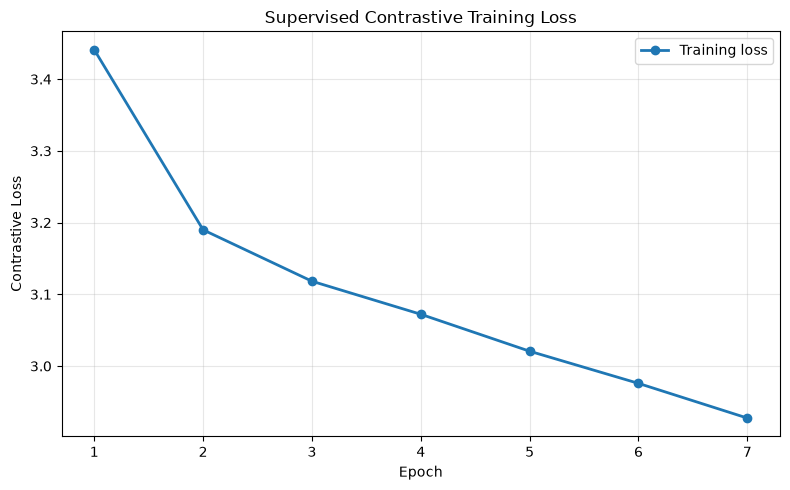

In [24]:
import pandas as pd
import matplotlib.pyplot as plt

history_df = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    linewidth=2,
    label="Training loss"
)

ax.set_title("Supervised Contrastive Training Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Contrastive Loss")
ax.set_xticks(history_df["epoch"])
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

Evaluate Training, Validation, and Baseline CLIP

In [25]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# ============================================
# 1. Load best trained model
# ============================================

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

head.load_state_dict(
    checkpoint["model_state_dict"]
)

head.eval()

print(
    "Loaded best model from epoch:",
    checkpoint["best_epoch"]
)

# ============================================
# 2. P@5 for already-normalized embeddings
# ============================================

@torch.inference_mode()
def precision_at_5_from_embeddings(
    embeddings,
    labels
):
    similarities = (
        embeddings @ embeddings.T
    )

    similarities.fill_diagonal_(
        -float("inf")
    )

    top_indices = similarities.topk(
        k=5,
        dim=1
    ).indices

    retrieved_labels = labels[
        top_indices
    ]

    relevant = (
        retrieved_labels
        == labels.unsqueeze(1)
    )

    return (
        relevant
        .float()
        .mean()
        .item()
    )

# ============================================
# 3. Original CLIP baseline P@5
# ============================================

baseline_train_p5 = (
    precision_at_5_from_embeddings(
        X_train,
        y_train
    )
)

baseline_val_p5 = (
    precision_at_5_from_embeddings(
        X_val,
        y_val
    )
)

# ============================================
# 4. Adapted model P@5
# ============================================

with torch.inference_mode():

    adapted_train_embeddings = head(
        X_train
    )

    adapted_val_embeddings = head(
        X_val
    )

adapted_train_p5 = (
    precision_at_5_from_embeddings(
        adapted_train_embeddings,
        y_train
    )
)

adapted_val_p5 = (
    precision_at_5_from_embeddings(
        adapted_val_embeddings,
        y_val
    )
)

generalization_gap = (
    adapted_train_p5
    - adapted_val_p5
)

# ============================================
# 5. Evaluation loss
#
# Use identical balanced 50-image batches
# for train and validation so the losses
# are directly comparable.
# ============================================

@torch.inference_mode()
def evaluate_supcon_loss(
    model,
    X,
    y,
    examples_per_style=10,
    temperature=0.1,
    seed=42
):

    model.eval()

    rng = np.random.default_rng(
        seed
    )

    y_numpy = (
        y.detach()
        .cpu()
        .numpy()
    )

    styles = np.unique(
        y_numpy
    )

    style_indices = {}

    for style in styles:

        indices = np.where(
            y_numpy == style
        )[0]

        indices = indices.copy()

        rng.shuffle(
            indices
        )

        style_indices[
            int(style)
        ] = indices

    num_batches = min(
        len(indices)
        // examples_per_style
        for indices
        in style_indices.values()
    )

    losses = []

    for batch_number in range(
        num_batches
    ):

        batch_indices = []

        for style in styles:

            start = (
                batch_number
                * examples_per_style
            )

            end = (
                start
                + examples_per_style
            )

            batch_indices.extend(
                style_indices[
                    int(style)
                ][start:end]
            )

        batch_indices = torch.tensor(
            batch_indices,
            dtype=torch.long,
            device=X.device
        )

        batch_X = X[
            batch_indices
        ]

        batch_y = y[
            batch_indices
        ]

        projected = model(
            batch_X
        )

        loss = supervised_contrastive_loss(
            projected,
            batch_y,
            temperature
        )

        losses.append(
            loss.item()
        )

    return float(
        np.mean(losses)
    )

# ============================================
# 6. Train and validation loss
# ============================================

train_loss = evaluate_supcon_loss(
    head,
    X_train,
    y_train,
    EXAMPLES_PER_STYLE,
    TEMPERATURE,
    SEED
)

val_loss = evaluate_supcon_loss(
    head,
    X_val,
    y_val,
    EXAMPLES_PER_STYLE,
    TEMPERATURE,
    SEED
)

# ============================================
# 7. Final results table
# ============================================

results_df = pd.DataFrame({
    "Model": [
        "Original CLIP",
        "Adapted CLIP"
    ],
    "Train P@5": [
        baseline_train_p5,
        adapted_train_p5
    ],
    "Validation P@5": [
        baseline_val_p5,
        adapted_val_p5
    ]
})

print("\n" + "=" * 55)
print("FINAL WIKIART EVALUATION")
print("=" * 55)

print("\nSUPERVISED CONTRASTIVE LOSS")
print("-" * 40)

print(
    f"Training loss:   "
    f"{train_loss:.4f}"
)

print(
    f"Validation loss: "
    f"{val_loss:.4f}"
)

print("\nADAPTED MODEL GENERALIZATION")
print("-" * 40)

print(
    f"Train P@5:       "
    f"{adapted_train_p5:.4f}"
)

print(
    f"Validation P@5:  "
    f"{adapted_val_p5:.4f}"
)

print(
    f"Gap:             "
    f"{generalization_gap:+.4f}"
)

print("\nBASELINE VS ADAPTED")
print("-" * 40)

print(
    f"Original CLIP validation P@5: "
    f"{baseline_val_p5:.4f}"
)

print(
    f"Adapted CLIP validation P@5:  "
    f"{adapted_val_p5:.4f}"
)

print(
    f"Absolute improvement:          "
    f"{adapted_val_p5 - baseline_val_p5:+.4f}"
)

display(
    results_df.round(4)
)

Loaded best model from epoch: 2

FINAL WIKIART EVALUATION

SUPERVISED CONTRASTIVE LOSS
----------------------------------------
Training loss:   3.0919
Validation loss: 3.0723

ADAPTED MODEL GENERALIZATION
----------------------------------------
Train P@5:       0.7347
Validation P@5:  0.7456
Gap:             -0.0109

BASELINE VS ADAPTED
----------------------------------------
Original CLIP validation P@5: 0.7264
Adapted CLIP validation P@5:  0.7456
Absolute improvement:          +0.0192


,Model,Train P@5,Validation P@5
0,Original CLIP,0.6602,0.7264
1,Adapted CLIP,0.7347,0.7456


Original CLIP vs Adapted CLIP Validation P@5

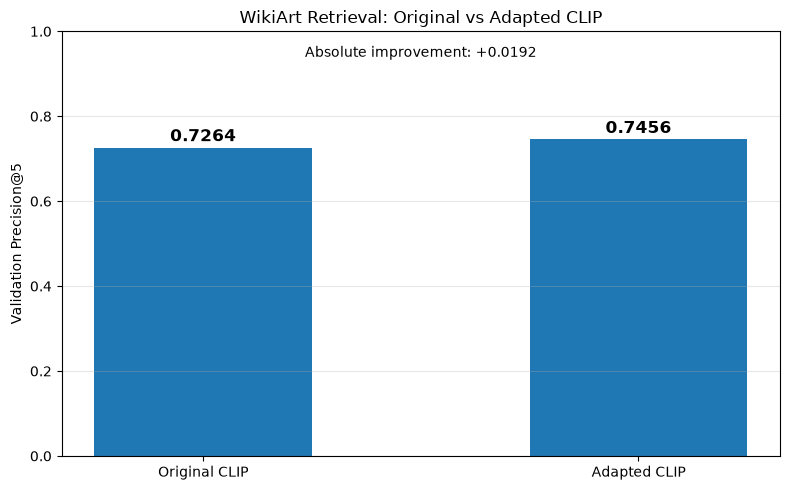

In [26]:
import matplotlib.pyplot as plt

models = ["Original CLIP", "Adapted CLIP"]

p5_scores = [
    baseline_val_p5,
    adapted_val_p5
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    models,
    p5_scores,
    width=0.5
)

for bar, score in zip(bars, p5_scores):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.015,
        f"{score:.4f}",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

improvement = adapted_val_p5 - baseline_val_p5

ax.set_title(
    "WikiArt Retrieval: Original vs Adapted CLIP"
)
ax.set_ylabel("Validation Precision@5")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

ax.text(
    0.5,
    0.94,
    f"Absolute improvement: {improvement:+.4f}",
    transform=ax.transAxes,
    ha="center"
)

plt.tight_layout()
plt.show()

Test Adapted Model on a Query Image

In [27]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

# ============================================
# 1. Paths
# ============================================

PROJECT_ROOT = Path(
    "/home/jovyan/AI_summer_shool_Aesha"
)

GALLERY_FEATURE_PATH = (
    PROJECT_ROOT
    / "embeddings"
    / "cu_clip_baseline.npz"
)

METADATA_PATH = (
    PROJECT_ROOT
    / "processed_gallery"
    / "gallery_metadata.csv"
)

GALLERY_IMAGE_ROOT = (
    PROJECT_ROOT
    / "processed_gallery"
    / "images"
)

CHECKPOINT_PATH = (
    PROJECT_ROOT
    / "models"
    / "retrieval_projection_head.pt"
)

MODEL_NAME = "openai/clip-vit-base-patch32"

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: cuda


Load CLIP and trained projection head

In [28]:
# ============================================
# 2. Load frozen CLIP
# ============================================

clip_model = CLIPModel.from_pretrained(
    MODEL_NAME
).to(device)

clip_processor = CLIPProcessor.from_pretrained(
    MODEL_NAME
)

clip_model.eval()

for parameter in clip_model.parameters():
    parameter.requires_grad = False


# ============================================
# 3. Projection head
# ============================================

class ProjectionHead(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 256)
        )

    def forward(self, x):

        x = self.network(x)

        return F.normalize(
            x,
            p=2,
            dim=1
        )


head = ProjectionHead().to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

head.load_state_dict(
    checkpoint["model_state_dict"]
)

head.eval()

print(
    "Projection head loaded from epoch:",
    checkpoint["best_epoch"]
)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Projection head loaded from epoch: 2


Load CU gallery and adapt it

In [29]:
# ============================================
# 4. Load CU baseline embeddings
# ============================================

gallery_data = np.load(
    GALLERY_FEATURE_PATH
)

gallery_features = torch.tensor(
    gallery_data["embeddings"],
    dtype=torch.float32,
    device=device
)

gallery_ids = gallery_data[
    "artwork_ids"
]

metadata = pd.read_csv(
    METADATA_PATH
)

print(
    "CU gallery:",
    gallery_features.shape
)

assert gallery_features.shape == (189, 512)


# ============================================
# 5. Apply trained head to CU gallery
# ============================================

with torch.inference_mode():

    adapted_gallery_features = head(
        gallery_features
    )

print(
    "Adapted CU gallery:",
    adapted_gallery_features.shape
)

assert adapted_gallery_features.shape == (
    189,
    256
)

CU gallery: torch.Size([189, 512])
Adapted CU gallery: torch.Size([189, 256])


Query retrieval function

In [30]:
# ============================================
# 6. Query feature extraction
# ============================================

@torch.inference_mode()
def get_clip_image_feature(image):

    if not isinstance(image, Image.Image):
        image = Image.open(image)

    image = image.convert("RGB")

    inputs = clip_processor(
        images=image,
        return_tensors="pt"
    )

    pixel_values = inputs[
        "pixel_values"
    ].to(device)

    vision_outputs = clip_model.vision_model(
        pixel_values=pixel_values
    )

    pooled_output = (
        vision_outputs.pooler_output
    )

    features = clip_model.visual_projection(
        pooled_output
    )

    features = F.normalize(
        features,
        p=2,
        dim=1
    )

    return features

In [31]:
# ============================================
# 7. Adapted retrieval
# ============================================

@torch.inference_mode()
def retrieve_adapted(
    query_image,
    top_k=5
):

    # Original 512-D CLIP feature
    query_clip = get_clip_image_feature(
        query_image
    )

    # Learned 256-D feature
    query_adapted = head(
        query_clip
    )

    # Cosine similarity because vectors
    # are L2-normalized
    similarities = (
        query_adapted
        @ adapted_gallery_features.T
    ).squeeze(0)

    top_scores, top_indices = torch.topk(
        similarities,
        k=top_k
    )

    results = []

    for rank, (
        index,
        score
    ) in enumerate(
        zip(
            top_indices.cpu().tolist(),
            top_scores.cpu().tolist()
        ),
        start=1
    ):

        artwork_id = str(
            gallery_ids[index]
        )

        row = metadata[
            metadata["artwork_id"].astype(str)
            == artwork_id
        ]

        if len(row) == 0:
            raise ValueError(
                f"Metadata missing for {artwork_id}"
            )

        row = row.iloc[0]

        results.append({
            "rank": rank,
            "artwork_id": artwork_id,
            "floor": row["floor"],
            "filename": row["filename"],
            "similarity": score
        })

    return pd.DataFrame(results)

Final Adapted ArtMatch Pipeline

In [32]:
def run_artmatch_adapted(
    query_image,
    top_k=5
):

    # =================================================
    # 1. Prepare query
    # =================================================

    if isinstance(
        query_image,
        (str, Path)
    ):

        query_image = Image.open(
            query_image
        ).convert("RGB")

    else:

        query_image = (
            query_image
            .convert("RGB")
        )

    # =================================================
    # 2. Retrieve using TRAINED projection head
    # =================================================

    results_df = retrieve_adapted(
        query_image,
        top_k=top_k
    )

    print(
        "Analyzing uploaded photograph..."
    )

    # =================================================
    # 3. Analyze query
    # =================================================

    query_attrs = analyze_artwork(
        query_image
    )

    image_list = [
        query_image
    ]

    titles = [
        "QUERY IMAGE"
    ]

    detailed_results = []

    # =================================================
    # 4. Analyze retrieved artworks
    # =================================================

    for row in results_df.itertuples():

        artwork_path = (
            GALLERY_IMAGE_ROOT
            / f"floor_{row.floor}"
            / row.filename
        )

        with Image.open(
            artwork_path
        ) as img:

            artwork_image = (
                img.convert("RGB")
            )

        attrs = analyze_artwork(
            artwork_image
        )

        image_list.append(
            artwork_image
        )

        titles.append(
            f"Rank {row.rank} | "
            f"{row.artwork_id}\n"
            f"Floor {row.floor} | "
            f"Similarity "
            f"{row.similarity:.3f}"
        )

        detailed_results.append({
            "Artwork ID":
                row.artwork_id,

            "Floor":
                row.floor,

            "Similarity":
                round(
                    row.similarity,
                    3
                ),

            **{
                key:
                    format_tags(value)

                for key, value
                in attrs.items()
            },

            "Shared with query":
                shared_features(
                    query_attrs,
                    attrs
                )
        })

    # =================================================
    # 5. Show query + retrieved artworks
    # =================================================

    fig, axes = plt.subplots(
        2,
        3,
        figsize=(16, 11)
    )

    for ax, image, title in zip(
        axes.flat,
        image_list,
        titles
    ):

        ax.imshow(
            image
        )

        ax.set_title(
            title,
            fontsize=11
        )

        ax.axis(
            "off"
        )

    plt.tight_layout()
    plt.show()

    # =================================================
    # 6. Query textual attributes
    # =================================================

    print(
        "\nQUERY IMAGE ATTRIBUTES"
    )

    print(
        "-" * 50
    )

    for key, value in (
        query_attrs.items()
    ):

        print(
            f"{key}: "
            f"{format_tags(value)}"
        )

    # =================================================
    # 7. Retrieved artwork textual attributes
    # =================================================

    print(
        "\nTOP 5 RETRIEVED ARTWORKS "
        "— ATTRIBUTE ANALYSIS"
    )

    print(
        "-" * 50
    )

    details_df = pd.DataFrame(
        detailed_results
    )

    for record in detailed_results:

        print(
            f"\n"
            f"{record['Artwork ID']} | "
            f"Floor {record['Floor']} | "
            f"Similarity "
            f"{record['Similarity']:.3f}"
        )

        for key, value in (
            record.items()
        ):

            if key not in [
                "Artwork ID",
                "Floor",
                "Similarity"
            ]:

                print(
                    f"  {key}: "
                    f"{value}"
                )

    return (
        results_df,
        details_df
    )

Attribute Analysis for Query and Retrieved Artworks

In [33]:
# =====================================================
# ZERO-SHOT ATTRIBUTE ANALYSIS
# =====================================================

ATTRIBUTES = {
    "category": [
        "cityscape",
        "landscape",
        "portrait",
        "still life",
        "abstract art",
        "architecture",
        "nature scene",
        "seascape",
        "animal painting",
        "figurative art"
    ],

    "objects": [
        "buildings",
        "houses",
        "windows",
        "roads",
        "streets",
        "trees",
        "flowers",
        "mountains",
        "water",
        "rivers",
        "sky",
        "clouds",
        "people",
        "animals",
        "cars",
        "bridges",
        "boats",
        "grass",
        "snow",
        "sun",
        "moon"
    ],

    "patterns": [
        "repeated geometric shapes",
        "repeated vertical lines",
        "repeated horizontal lines",
        "curved flowing lines",
        "strong linear perspective",
        "symmetrical composition",
        "irregular abstract shapes",
        "dense detailed composition",
        "minimalist composition",
        "contrasting color blocks"
    ],

    "season": [
        "spring",
        "summer",
        "autumn",
        "winter"
    ],

    "time": [
        "daytime",
        "sunrise",
        "sunset",
        "nighttime"
    ],

    "mood": [
        "calm",
        "cheerful",
        "peaceful",
        "energetic",
        "melancholic",
        "mysterious",
        "dramatic",
        "tense"
    ],

    "style": [
        "realism",
        "impressionism",
        "expressionism",
        "abstract art",
        "cubism",
        "surrealism",
        "pop art",
        "watercolor illustration",
        "folk art",
        "modern art"
    ]
}


# =====================================================
# 1. Cached CLIP text embeddings
# =====================================================

text_cache = {}


@torch.inference_mode()
def get_text_embeddings(prompts):

    key = tuple(prompts)

    if key in text_cache:
        return text_cache[key]

    inputs = clip_processor(
        text=list(prompts),
        return_tensors="pt",
        padding=True,
        truncation=True
    )

    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)

    text_outputs = clip_model.text_model(
        input_ids=input_ids,
        attention_mask=attention_mask
    )

    pooled_output = text_outputs.pooler_output

    features = clip_model.text_projection(
        pooled_output
    )

    features = F.normalize(
        features,
        p=2,
        dim=1
    )

    text_cache[key] = features

    return features


# =====================================================
# 2. Zero-shot prediction helpers
# =====================================================

def predict_single(
    embedding,
    labels,
    template,
    cautious=False
):

    prompts = [
        template.format(label)
        for label in labels
    ]

    text_features = get_text_embeddings(
        prompts
    )

    scores = (
        embedding
        @ text_features.T
    ).flatten()

    order = torch.argsort(
        scores,
        descending=True
    )

    best = int(
        order[0].item()
    )

    if cautious and len(order) > 1:

        margin = (
            scores[order[0]]
            - scores[order[1]]
        ).item()

        if margin < 0.015:
            return "Unclear"

    return labels[
        best
    ].title()


def predict_multi(
    embedding,
    labels,
    max_tags=5
):

    predictions = []

    for label in labels:

        prompts = [
            f"An image containing {label}.",
            f"An image without {label}."
        ]

        text_features = get_text_embeddings(
            prompts
        )

        scores = (
            embedding
            @ text_features.T
        ).flatten()

        margin = (
            scores[0]
            - scores[1]
        ).item()

        if margin > 0.015:
            predictions.append(
                (label, margin)
            )

    predictions.sort(
        key=lambda item: item[1],
        reverse=True
    )

    return [
        label
        for label, _
        in predictions[:max_tags]
    ]


# =====================================================
# 3. Pixel-based color analysis
# =====================================================

COLOR_PALETTE = {
    "Red": (210, 55, 55),
    "Orange": (235, 135, 45),
    "Yellow": (235, 215, 65),
    "Green": (60, 150, 75),
    "Blue": (55, 115, 205),
    "Purple": (140, 80, 175),
    "Pink": (230, 135, 175),
    "Brown": (125, 80, 50),
    "Black": (25, 25, 25),
    "White": (240, 240, 240),
    "Gray": (140, 140, 140),
    "Beige": (210, 190, 155)
}


# def analyze_colors(image):

#     import colorsys

#     small = image.convert(
#         "RGB"
#     ).resize(
#         (100, 100)
#     )

#     pixels = np.asarray(
#         small,
#         dtype=np.float32
#     ).reshape(
#         -1,
#         3
#     )

#     names = list(
#         COLOR_PALETTE.keys()
#     )

#     reference = np.array(
#         list(
#             COLOR_PALETTE.values()
#         ),
#         dtype=np.float32
#     )

#     distances = np.sum(
#         (
#             pixels[:, None, :]
#             - reference[None, :, :]
#         ) ** 2,
#         axis=2
#     )

#     nearest = np.argmin(
#         distances,
#         axis=1
#     )

#     counts = np.bincount(
#         nearest,
#         minlength=len(names)
#     )

#     ranked = np.argsort(
#         counts
#     )[::-1]

#     dominant = [
#         names[i]
#         for i in ranked[:3]
#     ]

#     sampled = (
#         pixels[::10]
#         / 255.0
#     )

#     warm = 0
#     cool = 0

#     for r, g, b in sampled:

#         h, s, v = colorsys.rgb_to_hsv(
#             r,
#             g,
#             b
#         )

#         if s < 0.18 or v < 0.15:
#             continue

#         degrees = h * 360

#         if degrees < 75 or degrees >= 330:
#             warm += 1

#         elif 75 <= degrees < 270:
#             cool += 1

#     total = warm + cool

#     if total < 50:
#         temperature = "Neutral / unclear"

#     else:

#         warm_ratio = (
#             warm / total
#         )

#         if warm_ratio >= 0.60:
#             temperature = "Mostly warm"

#         elif warm_ratio <= 0.40:
#             temperature = "Mostly cool"

#         else:
#             temperature = "Mixed"

#     return (
#         dominant,
#         temperature
#     )


def analyze_colors(image):
    import colorsys
    from collections import Counter

    image = image.convert("RGB")
    image = image.resize((150, 150))

    pixels = np.asarray(
        image, dtype=np.float32
    ).reshape(-1, 3) / 255.0

    counts = Counter()
    warm = 0
    cool = 0

    for r, g, b in pixels:
        h, s, v = colorsys.rgb_to_hsv(r, g, b)
        hue = h * 360

        # Neutral colors
        if v < 0.16:
            color = "Black"
        elif s < 0.14:
            if v > 0.88:
                color = "White"
            else:
                color = "Gray"

        # Dark, earthy colors
        elif 12 <= hue < 45 and v < 0.55:
            color = "Brown"

        # Saturated colors
        elif hue < 12 or hue >= 345:
            color = "Red"
        elif hue < 45:
            color = "Orange"
        elif hue < 70:
            color = "Yellow"
        elif hue < 170:
            color = "Green"
        elif hue < 195:
            color = "Cyan"
        elif hue < 255:
            color = "Blue"
        elif hue < 290:
            color = "Purple"
        elif hue < 345:
            color = "Pink"
        else:
            color = "Unclear"

        counts[color] += 1

        # Temperature is based on chromatic pixels
        if s >= 0.20 and v >= 0.20:
            if hue < 75 or hue >= 330:
                warm += 1
            elif 75 <= hue < 270:
                cool += 1

    total_pixels = len(pixels)

    # Select prominent colors, rather than always
    # forcing exactly three colors.
    dominant = [
        name
        for name, count in counts.most_common()
        if count / total_pixels >= 0.08
    ][:4]

    if not dominant:
        dominant = [
            name for name, _ in counts.most_common(3)
        ]

    total = warm + cool

    if total == 0:
        temperature = "Neutral / unclear"
    else:
        warm_ratio = warm / total

        if warm_ratio >= 0.60:
            temperature = "Mostly warm"
        elif warm_ratio <= 0.40:
            temperature = "Mostly cool"
        else:
            temperature = "Mixed"

    return dominant, temperature



# =====================================================
# 4. Complete image attribute analysis
# =====================================================

def analyze_artwork(image):

    image = image.convert(
        "RGB"
    )

    embedding = get_clip_image_feature(
        image
    )

    category = predict_single(
        embedding,
        ATTRIBUTES["category"],
        "An image depicting {}."
    )

    # objects = predict_multi(
    #     embedding,
    #     ATTRIBUTES["objects"],
    #     max_tags=6
    # )


    # Object labels can be misleading for nonrepresentational art.
    # Prefer no object claim for images categorized as abstract.
    if category == "Abstract Art":
        objects = []
    else:
        objects = predict_multi(
            embedding,
            ATTRIBUTES["objects"],
            max_tags=3
        )


    patterns = predict_multi(
        embedding,
        ATTRIBUTES["patterns"],
        max_tags=3
    )

    colors, temperature = (
        analyze_colors(image)
    )

    season = predict_single(
        embedding,
        ATTRIBUTES["season"],
        "A scene depicting {}.",
        cautious=True
    )

    time_of_day = predict_single(
        embedding,
        ATTRIBUTES["time"],
        "A scene during {}.",
        cautious=True
    )

    mood = predict_single(
        embedding,
        ATTRIBUTES["mood"],
        "An image with a {} mood.",
        cautious=True
    )

    style = predict_single(
        embedding,
        ATTRIBUTES["style"],
        "An artwork in the style of {}.",
        cautious=True
    )

    if category in [
        "Abstract Art",
        "Still Life",
        "Portrait"
    ]:
        season = "Not determined"
        time_of_day = "Not determined"

    return {
        "Category": category,
        "Main colors": colors,
        "Color temperature": temperature,
        "Visible objects": objects,
        "Patterns": patterns,
        "Season": season,
        "Time of day": time_of_day,
        "Possible mood": mood,
        "Apparent style": style
    }


# =====================================================
# 5. Shared features
# =====================================================

def shared_features(
    query_attrs,
    artwork_attrs
):

    shared = []

    for field in [
        "Main colors",
        "Visible objects",
        "Patterns"
    ]:

        common = (
            set(query_attrs[field])
            & set(artwork_attrs[field])
        )

        if common:

            shared.append(
                f"{field}: "
                f"{', '.join(sorted(common))}"
            )

    if shared:
        return "; ".join(shared)

    return "No shared tags detected"


def format_tags(values):

    if isinstance(
        values,
        list
    ):

        if values:
            return ", ".join(values)

        return (
            "None confidently selected"
        )

    return str(values)

Interactive Query Demo

In [34]:
import io
import ipywidgets as widgets

from IPython.display import (
    display,
    clear_output
)


upload_widget = widgets.FileUpload(
    accept="image/*",
    multiple=False,
    description="Upload Image"
)

analysis_output = widgets.Output()


def handle_upload(change):

    if not upload_widget.value:
        return

    with analysis_output:

        clear_output(
            wait=True
        )

        try:

            uploaded_file = next(
                iter(
                    upload_widget.value
                )
            )

            content = bytes(
                uploaded_file[
                    "content"
                ]
            )

            query_image = Image.open(
                io.BytesIO(
                    content
                )
            ).convert(
                "RGB"
            )

            print(
                "Processing query image..."
            )

            run_artmatch_adapted(
                query_image,
                top_k=5
            )

        except Exception as error:

            print(
                "Processing failed:",
                str(error)
            )


upload_widget.observe(
    handle_upload,
    names="value"
)


display(
    widgets.HTML(
        "<h3>"
        "ArtMatch Campus - "
        "Adapted Artwork Discovery"
        "</h3>"
        "<p>"
        "Upload an image to retrieve "
        "the five most related CU artworks "
        "and view their predicted attributes."
        "</p>"
    ),
    upload_widget,
    analysis_output
)

HTML(value='<h3>ArtMatch Campus - Adapted Artwork Discovery</h3><p>Upload an image to retrieve the five most r…

FileUpload(value=(), accept='image/*', description='Upload Image')

Output()

In [35]:

import io
import base64
import html
import gradio as gr
from PIL import Image

# ======================================================
# ARTMATCH CAMPUS — SIMPLE BROWSER UI
# ======================================================

def image_to_data_url(image):
    """Embed an image directly in a result card."""
    buffer = io.BytesIO()
    image.convert("RGB").save(
        buffer, format="JPEG", quality=85
    )
    encoded = base64.b64encode(
        buffer.getvalue()
    ).decode("ascii")
    return f"data:image/jpeg;base64,{encoded}"


def safe_text(value):
    if isinstance(value, (list, tuple)):
        value = ", ".join(map(str, value)) if value else "Not detected"
    return html.escape(str(value))


def attribute_html(attributes):
    """Create compact, readable attribute rows."""
    rows = []

    for key, value in attributes.items():
        rows.append(
            "<div style='margin:5px 0;line-height:1.5;'>"
            f"<strong>{safe_text(key)}:</strong> "
            f"{safe_text(value)}"
            "</div>"
        )

    return "".join(rows)


def search_artmatch(query_image):

    if query_image is None:
        raise gr.Error("Please upload an image first.")

    query_image = query_image.convert("RGB")

    # Existing trained retrieval model
    results_df = retrieve_adapted(
        query_image, top_k=5
    )

    # Existing zero-shot attribute analysis
    query_attributes = analyze_artwork(query_image)

    query_html = f"""
    <div style="
        background:#f8fafc;
        color:#182231;
        border:1px solid #dbe2ea;
        border-radius:12px;
        padding:16px;
    ">
        <h3 style="margin:0 0 12px;">
            Your Image Analysis
        </h3>
        {attribute_html(query_attributes)}
    </div>
    """

    cards = []

    for row in results_df.itertuples():

        image_path = (
            GALLERY_IMAGE_ROOT
            / f"floor_{row.floor}"
            / row.filename
        )

        with Image.open(image_path) as image:
            artwork_image = image.convert("RGB").copy()

        attributes = analyze_artwork(artwork_image)

        shared = shared_features(
            query_attributes, attributes
        )

        artwork_src = image_to_data_url(artwork_image)

        card = f"""
        <div style="
            display:flex;
            flex-wrap:wrap;
            gap:20px;
            background:#ffffff;
            color:#182231;
            border:1px solid #dbe2ea;
            border-radius:14px;
            padding:18px;
            margin-bottom:16px;
        ">

            <div style="
                flex:0 1 240px;
                min-width:180px;
                max-width:100%;
            ">
                <img
                    src="{artwork_src}"
                    alt="Artwork {safe_text(row.artwork_id)}"
                    style="
                        width:100%;
                        height:230px;
                        object-fit:contain;
                        background:#f1f5f9;
                        border-radius:10px;
                    "
                >
            </div>

            <div style="
                flex:1 1 260px;
                min-width:0;
            ">
                <h3 style="margin:0 0 8px;">
                    #{int(row.rank)} — {safe_text(row.artwork_id)}
                </h3>

                <div style="margin-bottom:12px;">
                    <strong>Location:</strong>
                    Floor {safe_text(row.floor)}
                    &nbsp; | &nbsp;
                    <strong>Similarity:</strong>
                    {float(row.similarity):.3f}
                </div>

                {attribute_html(attributes)}

                <div style="
                    margin-top:12px;
                    padding:10px;
                    background:#f1f5f9;
                    border-radius:8px;
                    line-height:1.5;
                ">
                    <strong>Shared with your image:</strong>
                    {safe_text(shared)}
                </div>
            </div>

        </div>
        """

        cards.append(card)

    results_html = (
        "<div style='font-family:Arial,sans-serif;'>"
        "<h2 style='margin-bottom:15px;'>"
        "Top 5 Related Artworks"
        "</h2>"
        + "".join(cards)
        + "</div>"
    )

    return query_html, results_html


def clear_artmatch():
    return None, "", ""


# ======================================================
# INTERFACE
# ======================================================

with gr.Blocks(
    title="ArtMatch Campus",
    css="""
    .gradio-container {
        max-width: 1050px !important;
        margin: auto !important;
    }
    """
) as demo:

    gr.Markdown(
        """
        # 🎨 ArtMatch Campus
        **Find campus artworks related to your photograph.**

        Upload an image and click **Find Artworks**.
        """
    )

    with gr.Row():

        with gr.Column(scale=1):

            query_input = gr.Image(
                label="Your Image",
                type="pil",
                sources=["upload"],
                height=250
            )

            find_button = gr.Button(
                "🔎 Find Artworks",
                variant="primary"
            )

            clear_button = gr.Button(
                "Clear / New Search"
            )

        with gr.Column(scale=1):

            query_output = gr.HTML(
                value=(
                    "<div style='padding:20px;"
                    "border:1px solid #dbe2ea;"
                    "border-radius:12px;'>"
                    "<strong>Your Image Analysis</strong>"
                    "<p>Results will appear here after searching.</p>"
                    "</div>"
                ),
                label="Query Details",
                show_label=False
            )

    result_output = gr.HTML(
        label="Retrieved Artwork Results",
        show_label=False
    )

    find_button.click(
        fn=search_artmatch,
        inputs=query_input,
        outputs=[
            query_output,
            result_output
        ],
        show_progress="full"
    )

    clear_button.click(
        fn=clear_artmatch,
        inputs=[],
        outputs=[
            query_input,
            query_output,
            result_output
        ]
    )

    gr.Markdown(
        """
        ---
        *Retrieval uses the trained CLIP projection head.
        Image attributes are estimated using zero-shot
        CLIP and color heuristics. Floor locations are
        taken from CU metadata.*
        """
    )

demo.launch(
    share=True,
    inline=False,
    show_error=True
)


/tmp/ipykernel_440002/1764089048.py:181: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7861

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


2026/10/15 00:26:15 [W] [service.go:132] login to server failed: dial tcp 44.237.78.176:7000: i/o timeout


In [37]:
# Stop the previous ArtMatch UI server, if it exists

if "ui_server" in globals():
    ui_server.shutdown()
    ui_server.server_close()
    print("Previous ArtMatch UI server stopped.")
else:
    print("No server reference found in this notebook.")

Previous ArtMatch UI server stopped.


In [38]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("/home/jovyan/AI_summer_shool_Aesha")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from artmatch_gallery_ui import start_artmatch_ui

ui_server = start_artmatch_ui(
    retrieve_adapted=retrieve_adapted,
    analyze_artwork=analyze_artwork,
    shared_features=shared_features,
    gallery_image_root=GALLERY_IMAGE_ROOT,
    port=8765
)

Local server: http://127.0.0.1:8765/
If the proxy link is unavailable, ask the server administrator whether Jupyter Server Proxy is enabled.
